# Flow Inversion on MNIST

Using the trained flows from the noise-variance sweep, we invert the forward pass via `inverse_step` to map real images back to the source distribution $p_0 = \mathcal{N}(0.5, \sigma^2 I)$ and inspect the recovered latent space.

In [1]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

from scipy.optimize import linear_sum_assignment
from scipy.spatial import distance

In [ ]:
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 150,
    'font.size': 13,
    'axes.titlesize': 15,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 17,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 2.0,
})

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [3]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


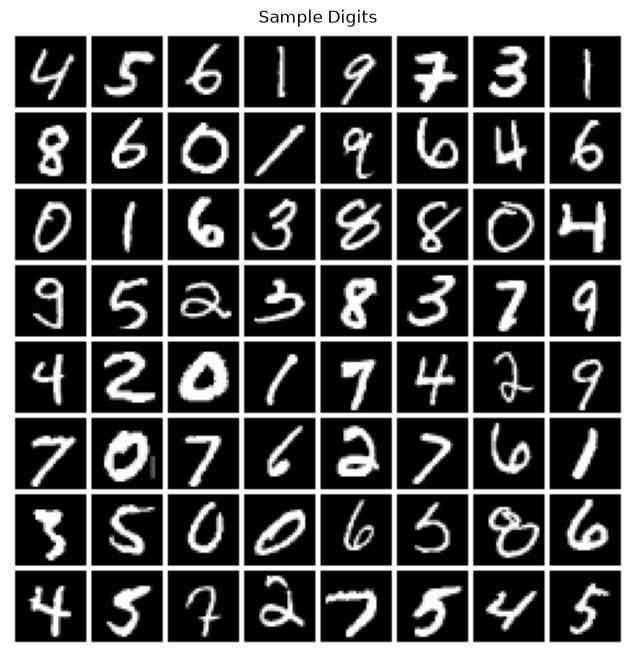

In [4]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

In [5]:
class Flow(nn.Module):

    def __init__(self, dim: int=28*28, h: int=128):
        super().__init__()
        self.dim = dim
        self.h = h

        self.net = nn.Sequential(
            nn.Linear(dim+1, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, h),
            nn.ReLU(),
            nn.Linear(h, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, dim),
        )
    def forward(self, x, t):
        x_t = torch.cat([x, t], dim=1)
        return self.net(x_t)

    def step(self, x_t: Tensor, t_start: float, t_end: float):
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t + self(x_t, t=t_start)*dt/2, t=(t_start + t_end)/2)

    def inverse_step(self, x_t: Tensor, t_start: float, t_end: float):
        t_end = t_end.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t - dt * self(x_t, t=t_end)



In [6]:
def train_flow(flow, train_loader, n_epochs=50, use_OT=True, lr=1e-3, sigma_noise=0.2, device=device):
    losses = []
    opt = torch.optim.Adam(flow.parameters(), lr=lr)
    for e in range(n_epochs):
        current_loss = 0.0
        for i, (x, _) in enumerate(train_loader):
            x_1 = x.view(-1, 784).to(device)

            t = torch.rand(x.shape[0], 1, device=x_1.device)
            x_0 = torch.randn_like(x_1)*sigma_noise + 0.5
            if use_OT:
                cost = distance.cdist(x_0.cpu().numpy(), x_1.cpu().numpy())
                row_ind, col_ind = linear_sum_assignment(cost)
                x_0, x_1 = x_0[row_ind], x_1[col_ind]
            dx_t = x_1 - x_0
            x_t = (1-t)*x_0 + t * x_1
            flow_pred = flow(x_t, t)

            loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
            loss.backward()
            opt.step()
            opt.zero_grad()

            current_loss += loss.item()
        avg_loss = current_loss / len(train_loader)
        losses.append(avg_loss)
        print(f'\r[{100*(e+1)/n_epochs:.0f}%] Epoch {e+1}/{n_epochs}  loss: {avg_loss:.4f}', end='', flush=True)

    return losses

In [15]:
SIGMA = 0.05

flow = Flow(h=64).to(device)
losses = train_flow(flow, train_loader, use_OT=False, n_epochs=50, lr=1e-3, sigma_noise=SIGMA, device=device)

flow_ot = Flow(h=64).to(device)
losses_ot = train_flow(flow_ot, train_loader, use_OT=True, n_epochs=50, lr=1e-3, sigma_noise=SIGMA, device=device)



[100%] Epoch 50/50  loss: 14.7094

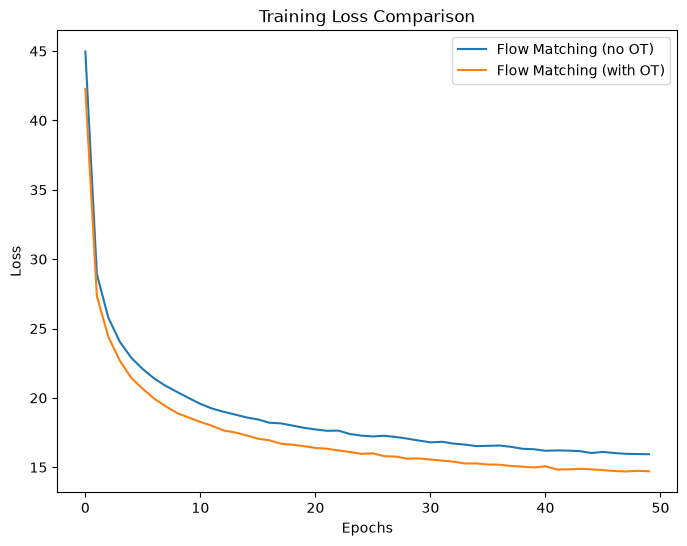

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(losses, label='Flow Matching (no OT)')
ax.plot(losses_ot, label='Flow Matching (with OT)')
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')
ax.set_title('Training Loss Comparison')
ax.legend()
plt.show();

### Flow inversion

In [ ]:
n_steps = 100
# inverse_step(x, t_start, t_end) undoes the forward step from t_start→t_end,
# so we iterate the same linspace(0,1) in reverse order.
time_steps = torch.linspace(0.0, 1.0, n_steps + 1)

inverted = []
inverted_ot = []
labels = []
train_images_display = None

with torch.no_grad():
    for x_batch, l_batch in train_loader:

        if train_images_display is None:
            train_images_display = x_batch[:16].view(-1, 1, 28, 28).detach().cpu()

        x = x_batch.view(-1, 784).to(device)
        x_ot = x_batch.view(-1, 784).to(device)
        for j in reversed(range(n_steps)):
            x = flow.inverse_step(x_t=x, t_start=time_steps[j].to(device), t_end=time_steps[j + 1].to(device))
            x_ot = flow_ot.inverse_step(x_t=x_ot, t_start=time_steps[j].to(device), t_end=time_steps[j + 1].to(device))
        inverted.append(x.cpu())
        inverted_ot.append(x_ot.cpu())
        labels.append(l_batch)

inverted = torch.cat(inverted, dim=0)
inverted_ot = torch.cat(inverted_ot, dim=0)
labels = torch.cat(labels, dim=0)



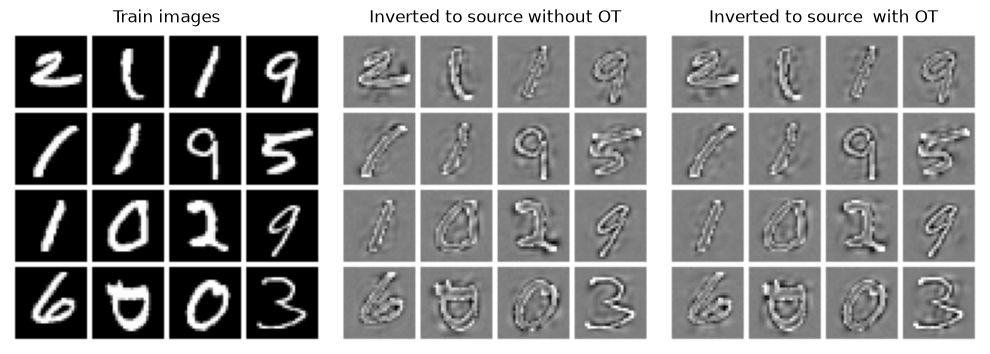

In [18]:
# Display first 16 test images alongside their inversions

fig, axes = plt.subplots(1, 3, figsize=(10, 8), squeeze=False)

show_samples(train_images_display, nrow=4, ax=axes[0, 0])
axes[0, 0].set_title(f'Train images')

show_samples(inverted[:16].view(-1, 1, 28, 28), nrow=4, ax=axes[0, 1])
axes[0, 1].set_title(f'Inverted to source without OT')

show_samples(inverted_ot[:16].view(-1, 1, 28, 28), nrow=4, ax=axes[0, 2])
axes[0, 2].set_title(f'Inverted to source  with OT')

plt.tight_layout()
plt.show()

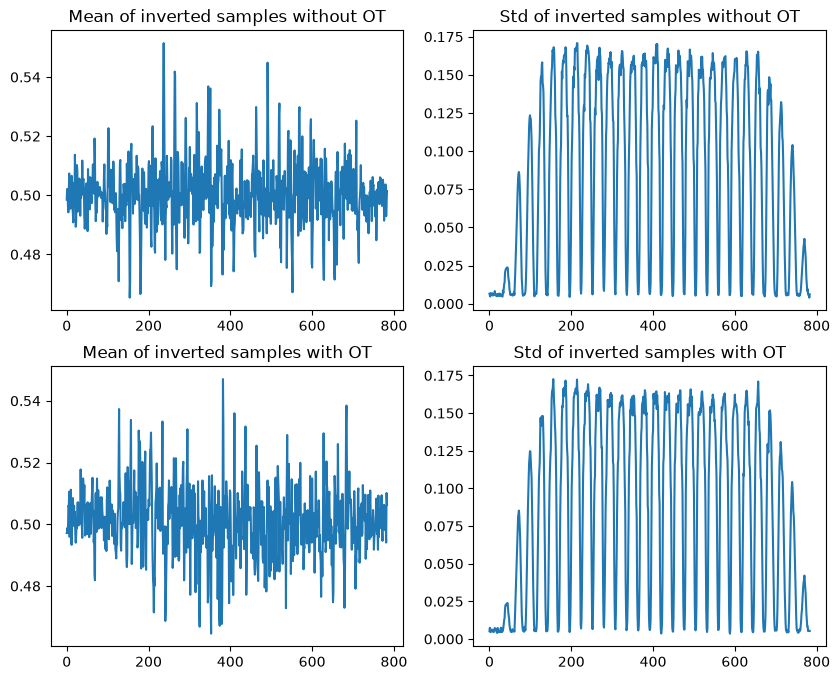

In [29]:
# Compute statistics of the inverted samples per channel for each sigma.

mu_channel = inverted.mean(dim=0)
sigma_channel = inverted.std(dim=0)
cov_channel = torch.cov(inverted.T)

mu_channel_ot = inverted_ot.mean(dim=0)
sigma_channel_ot = inverted_ot.std(dim=0)
cov_channel_ot = torch.cov(inverted_ot.T)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), squeeze=False)


axes[0, 0].plot(mu_channel.cpu().numpy())
axes[0, 0].set_title(f'Mean of inverted samples without OT')

axes[0, 1].plot(sigma_channel.cpu().numpy())
axes[0, 1].set_title(f'Std of inverted samples without OT')

axes[1, 0].plot(mu_channel_ot.cpu().numpy())
axes[1, 0].set_title(f'Mean of inverted samples with OT')

axes[1, 1].plot(sigma_channel_ot.cpu().numpy())
axes[1, 1].set_title(f'Std of inverted samples with OT')



plt.show();

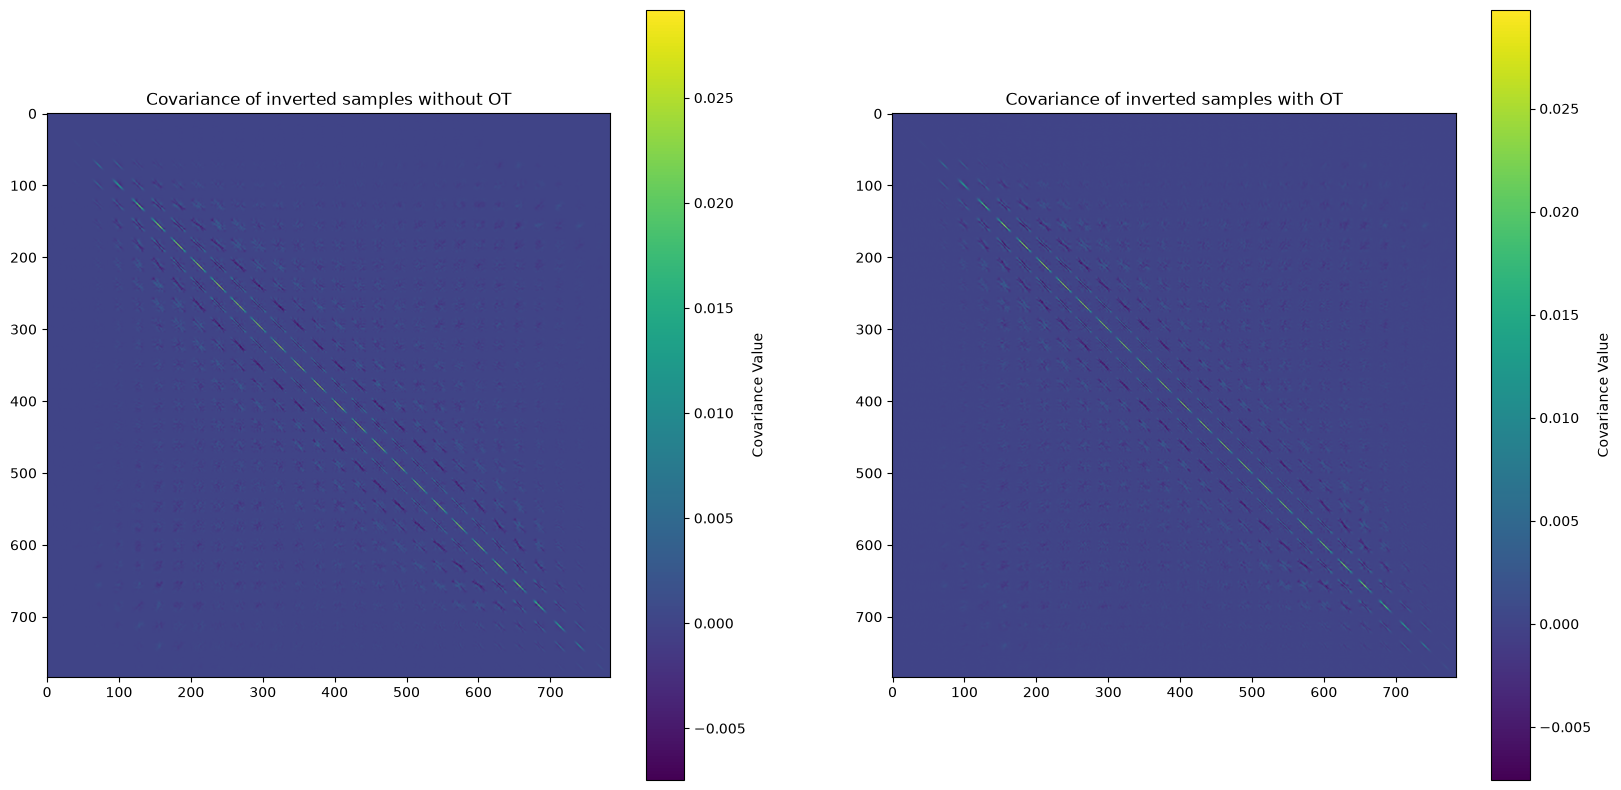

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(20, 10), squeeze=False)

axes[0, 0].imshow(cov_channel.cpu().numpy())
axes[0, 0].set_title(f'Covariance of inverted samples without OT')
# Add colorbar for covariance matrix
cbar = plt.colorbar(axes[0, 0].imshow(cov_channel.cpu().numpy()), ax=axes[0, 0])
cbar.set_label('Covariance Value')


axes[0, 1].imshow(cov_channel_ot.cpu().numpy())
axes[0, 1].set_title(f'Covariance of inverted samples with OT')
# Add colorbar for covariance matrix
cbar = plt.colorbar(axes[0, 1].imshow(cov_channel_ot.cpu().numpy()), ax=axes[0, 1])
cbar.set_label('Covariance Value')

plt.show();

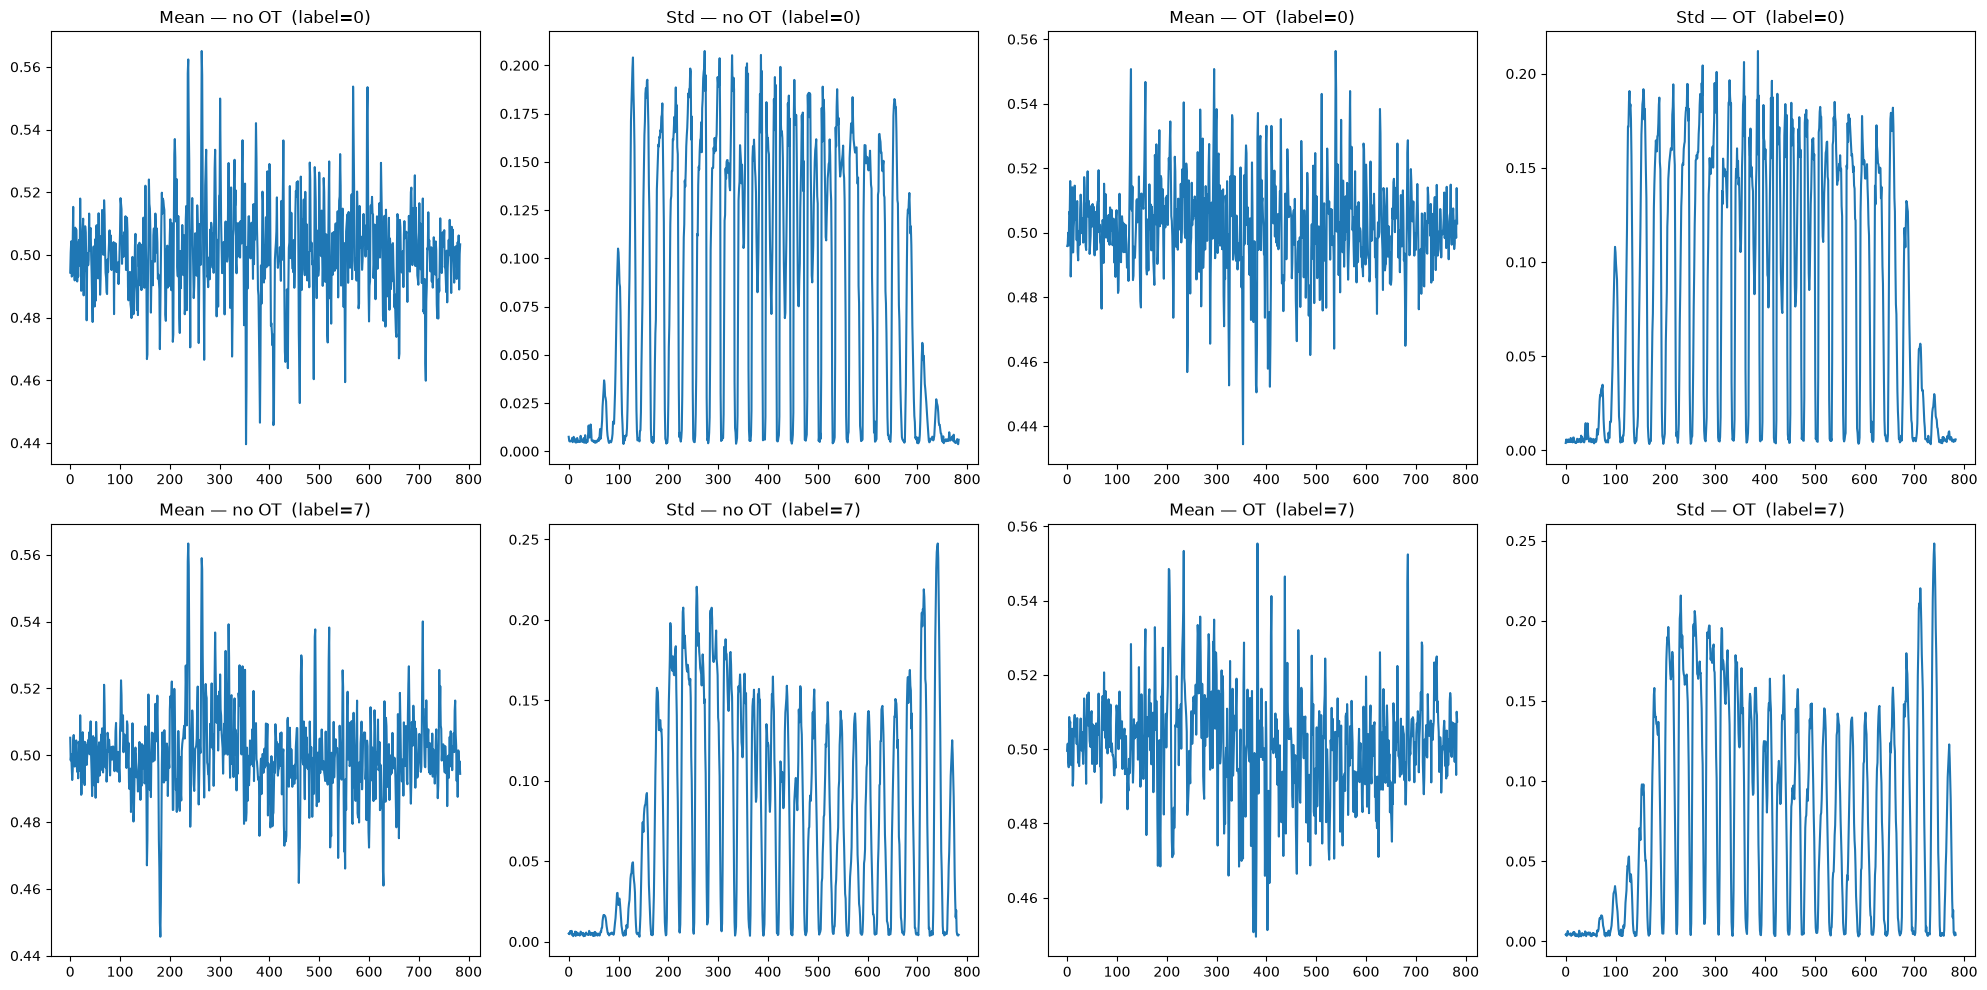

In [31]:
# Repeat the plots for a couple of labels
LABELS = [0, 7]

fig, axes = plt.subplots(len(LABELS), 4, figsize=(20, 5 * len(LABELS)), squeeze=False)

for row, lbl in enumerate(LABELS):
    mask = labels == lbl

    mu        = inverted[mask].mean(dim=0)
    sigma_std = inverted[mask].std(dim=0)
    mu_ot     = inverted_ot[mask].mean(dim=0)
    sigma_ot  = inverted_ot[mask].std(dim=0)

    axes[row, 0].plot(mu.numpy())
    axes[row, 0].set_title(f'Mean — no OT  (label={lbl})')

    axes[row, 1].plot(sigma_std.numpy())
    axes[row, 1].set_title(f'Std — no OT  (label={lbl})')

    axes[row, 2].plot(mu_ot.numpy())
    axes[row, 2].set_title(f'Mean — OT  (label={lbl})')

    axes[row, 3].plot(sigma_ot.numpy())
    axes[row, 3].set_title(f'Std — OT  (label={lbl})')

plt.tight_layout()
plt.show()

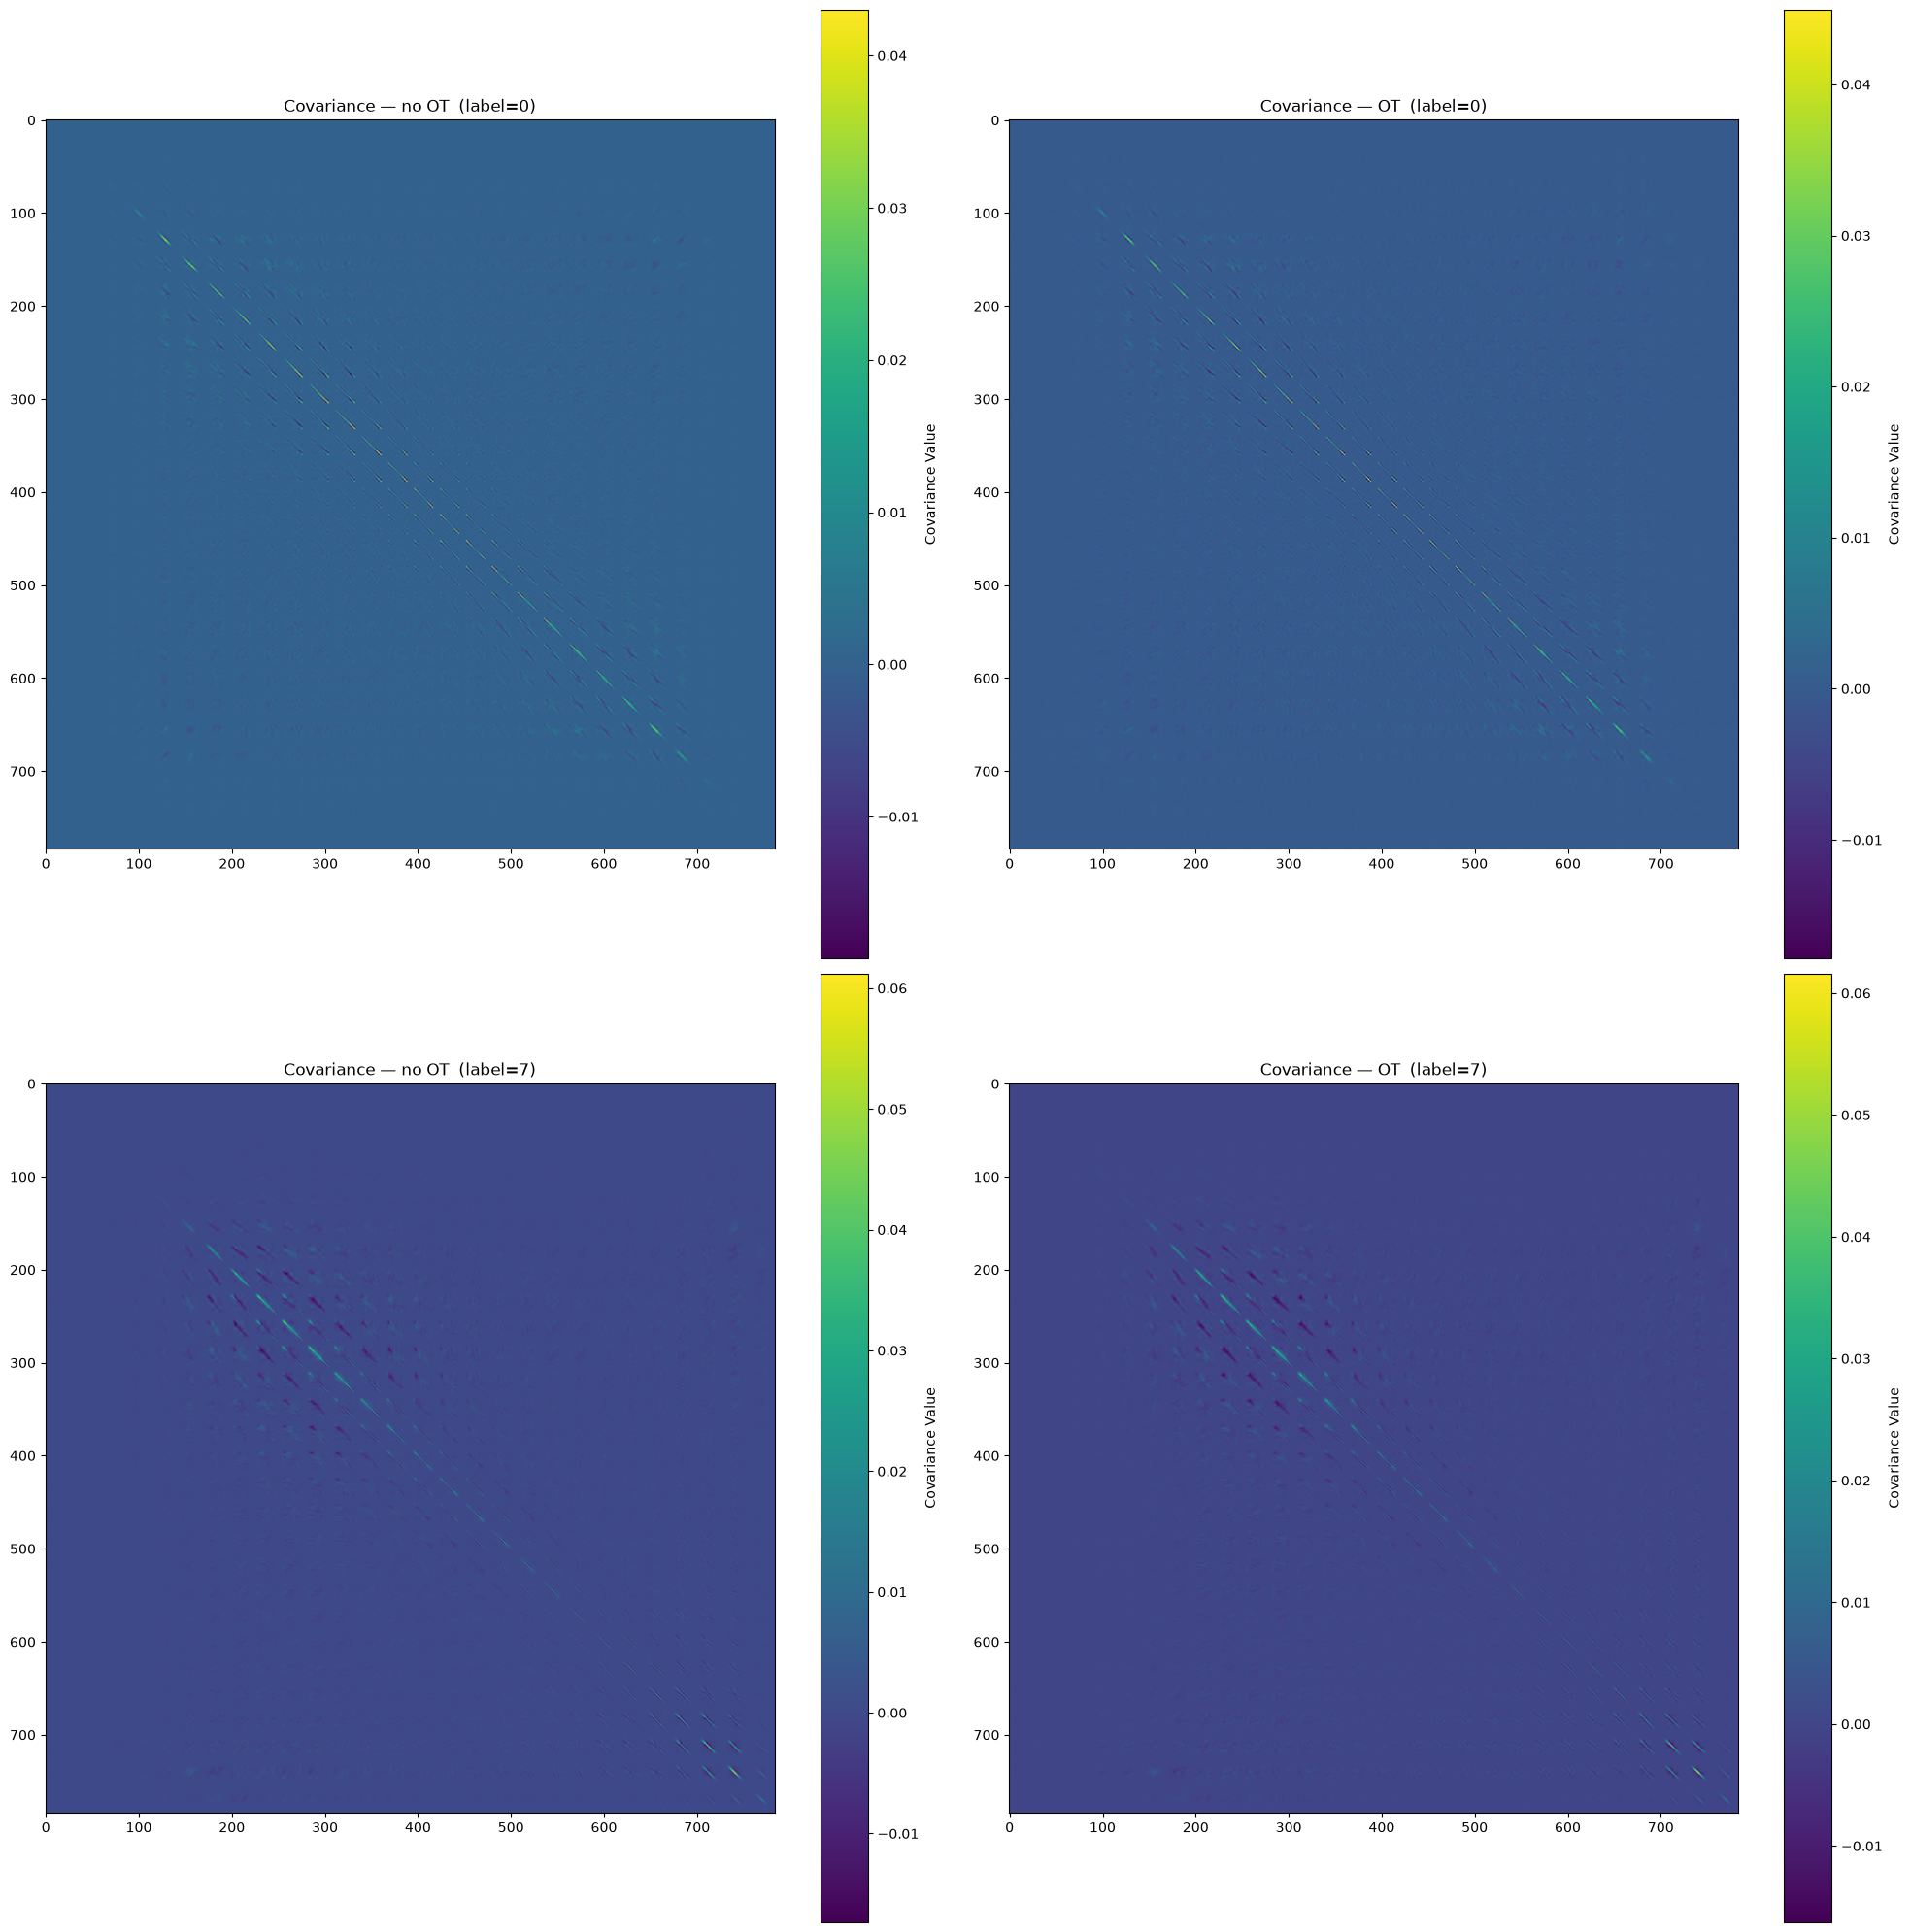

In [32]:
fig, axes = plt.subplots(len(LABELS), 2, figsize=(20, 10 * len(LABELS)), squeeze=False)

for row, lbl in enumerate(LABELS):
    mask = labels == lbl

    cov    = torch.cov(inverted[mask].T)
    cov_ot = torch.cov(inverted_ot[mask].T)

    im0 = axes[row, 0].imshow(cov.numpy())
    axes[row, 0].set_title(f'Covariance — no OT  (label={lbl})')
    plt.colorbar(im0, ax=axes[row, 0]).set_label('Covariance Value')

    im1 = axes[row, 1].imshow(cov_ot.numpy())
    axes[row, 1].set_title(f'Covariance — OT  (label={lbl})')
    plt.colorbar(im1, ax=axes[row, 1]).set_label('Covariance Value')

plt.tight_layout()
plt.show()

### Time embedding

In [33]:
def get_fourier_features(t, num_frequencies=16):
    frequencies = torch.logspace(0, 1, num_frequencies)
    features = torch.cat([torch.sin(2 * np.pi * f * t) for f in frequencies] + [torch.cos(2 * np.pi * f * t) for f in frequencies], dim=-1)
    return features

In [34]:
class Flow(nn.Module):

    def __init__(self, dim: int=28*28, h: int=128, t_embedding_dim: int=32):
        super().__init__()
        self.dim = dim
        self.h = h
        self.t_embedding_dim = t_embedding_dim

        self.net = nn.Sequential(
            nn.Linear(dim + t_embedding_dim, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, h),
            nn.ReLU(),
            nn.Linear(h, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, dim),
        )
    def forward(self, x, t):
        t_embedding = get_fourier_features(t, num_frequencies=self.t_embedding_dim // 2)
        x_t = torch.cat([x, t_embedding], dim=1)
        return self.net(x_t)

    def step(self, x_t: Tensor, t_start: float, t_end: float):
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t + self(x_t, t=t_start)*dt/2, t=(t_start + t_end)/2)

    def inverse_step(self, x_t: Tensor, t_start: float, t_end: float):
        t_end = t_end.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t - dt * self(x_t, t=t_end)

In [39]:
flow_t = Flow(h=64, t_embedding_dim=128).to(device)
losses_t = train_flow(flow_t, train_loader, use_OT=True, n_epochs=50, lr=1e-3, sigma_noise=SIGMA, device=device)

[100%] Epoch 50/50  loss: 14.4451

In [40]:
n_steps = 100
# inverse_step(x, t_start, t_end) undoes the forward step from t_start→t_end,
# so we iterate the same linspace(0,1) in reverse order.
time_steps = torch.linspace(0.0, 1.0, n_steps + 1)

inverted_t = []
labels = []
train_images_display = None

with torch.no_grad():
    for x_batch, l_batch in train_loader:

        if train_images_display is None:
            train_images_display = x_batch[:16].view(-1, 1, 28, 28).detach().cpu()

        x = x_batch.view(-1, 784).to(device)
        x_ot = x_batch.view(-1, 784).to(device)
        for j in reversed(range(n_steps)):
            x = flow_t.inverse_step(x_t=x, t_start=time_steps[j].to(device), t_end=time_steps[j + 1].to(device))
        inverted_t.append(x.cpu())
        labels.append(l_batch)

inverted_t = torch.cat(inverted_t, dim=0)
labels = torch.cat(labels, dim=0)


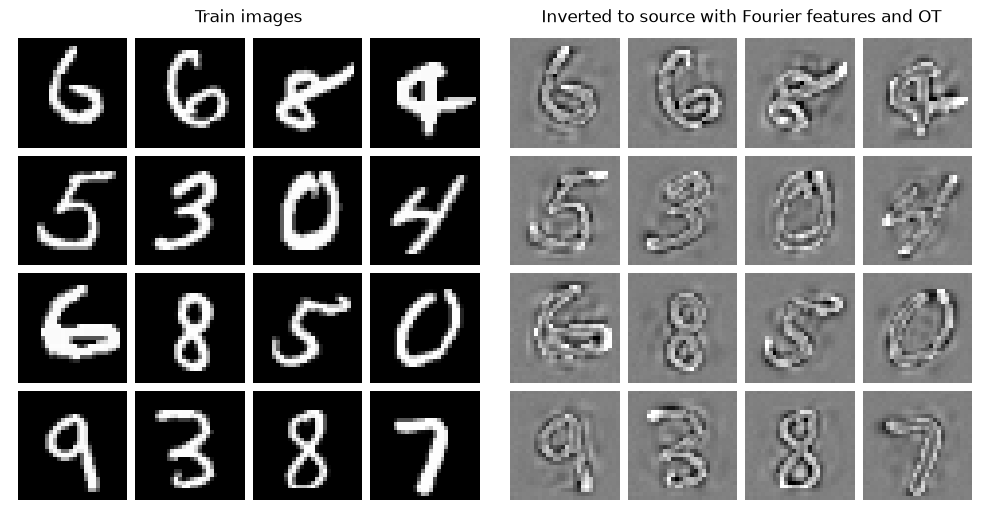

In [41]:
# Display first 16 test images alongside their inversions

fig, axes = plt.subplots(1, 2, figsize=(10, 8), squeeze=False)

show_samples(train_images_display, nrow=4, ax=axes[0, 0])
axes[0, 0].set_title(f'Train images')

show_samples(inverted_t[:16].view(-1, 1, 28, 28), nrow=4, ax=axes[0, 1])
axes[0, 1].set_title(f'Inverted to source with Fourier features and OT')

plt.tight_layout()
plt.show()